# 07 — Mini benchmark and model-family screening

**Task:** multiclass classification — sleep-profile prediction

This notebook compares a compact set of classical supervised-learning families on the frozen
`TRAIN` and `VALIDATION` partitions produced by the end-to-end preparation workflow.

The purpose is **screening**, not formal tuning:

- test several model families;
- expose each family to a few reasonable manual hyperparameter settings;
- compare macro and class-level behavior;
- inspect training-versus-validation gaps;
- select the **top three algorithm families** for later hyperparameter optimization.

TEST is intentionally excluded.

## Evaluation boundary

```text
TRAIN      -> fit candidate estimators
VALIDATION -> compare candidates and select families
TEST       -> protected; not loaded
```

We use the model-ready matrices created by notebook 06. Those matrices were produced by a
preparation workflow fitted only on TRAIN.

This fixed representation is appropriate for the current fixed-holdout screening. When formal
hyperparameter optimization begins, the **unfitted preparation template** must be combined with
each candidate estimator and fitted independently inside every cross-validation training fold.

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
PASTEL_CMAP = sns.light_palette("#6C8EBF", as_cmap=True)
RANDOM_STATE = 42

In [2]:
def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Repository root could not be located.")

ROOT = find_repo_root()
DATASET = "synthetic_sleep_profiles"
TASK_DIR = ROOT / "results" / DATASET / "model_screening"
FIG_DIR = TASK_DIR / "figures"
TABLE_DIR = TASK_DIR / "tables"

for path in [TASK_DIR, FIG_DIR, TABLE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = ROOT / "data" / DATASET / "ml_ready" / "train_ready.csv"
VALIDATION_PATH = ROOT / "data" / DATASET / "ml_ready" / "validation_ready.csv"
MANIFEST_PATH = ROOT / "results" / DATASET / "ml_preparation" / "preparation_manifest.json"
FITTED_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_fitted.joblib"
TEMPLATE_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_template.joblib"
TARGET_ENCODER_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "target_label_encoder.joblib"

for required in [
    TRAIN_PATH,
    VALIDATION_PATH,
    MANIFEST_PATH,
    FITTED_PREPARATION_PATH,
    TEMPLATE_PREPARATION_PATH,
    TARGET_ENCODER_PATH,
]:
    if not required.exists():
        raise FileNotFoundError(
            f"Missing required artifact: {required}\n"
            "Run notebook 06_end_to_end_ml_preparation.ipynb first."
        )

print("Repository:", ROOT)
print("TRAIN:", TRAIN_PATH.relative_to(ROOT))
print("VALIDATION:", VALIDATION_PATH.relative_to(ROOT))
print("TEST is intentionally not loaded in this notebook.")

Repository: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
TRAIN: data/synthetic_sleep_profiles/ml_ready/train_ready.csv
VALIDATION: data/synthetic_sleep_profiles/ml_ready/validation_ready.csv
TEST is intentionally not loaded in this notebook.


In [3]:
with MANIFEST_PATH.open("r", encoding="utf-8") as handle:
    manifest = json.load(handle)

fitted_preparation = joblib.load(FITTED_PREPARATION_PATH)
preparation_template = joblib.load(TEMPLATE_PREPARATION_PATH)
target_encoder = joblib.load(TARGET_ENCODER_PATH)

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)

ID_COL = manifest["identifier"]
TARGET_TEXT = manifest["target"]
TARGET = "sleep_profile_encoded"
SELECTED_FEATURES = manifest["selected_features"]

expected_columns = [ID_COL, *SELECTED_FEATURES, TARGET_TEXT, TARGET]
assert not (set(expected_columns) - set(train_df.columns))
assert not (set(expected_columns) - set(val_df.columns))

X_train = train_df[SELECTED_FEATURES].copy()
y_train = train_df[TARGET].astype(int).copy()
X_val = val_df[SELECTED_FEATURES].copy()
y_val = val_df[TARGET].astype(int).copy()

CLASS_IDS = np.arange(len(target_encoder.classes_))
CLASS_NAMES = list(target_encoder.classes_)

print(f"TRAIN:      X={X_train.shape}, y={y_train.shape}")
print(f"VALIDATION: X={X_val.shape}, y={y_val.shape}")
print("Classes:", dict(zip(CLASS_IDS, CLASS_NAMES)))

TRAIN:      X=(840, 16), y=(840,)
VALIDATION: X=(180, 16), y=(180,)
Classes: {np.int64(0): 'circadian_disruption', np.int64(1): 'healthy_sleep', np.int64(2): 'insomnia', np.int64(3): 'sleep_apnea'}


In [4]:
class_summary = pd.concat(
    [
        y_train.value_counts(normalize=True).sort_index().rename("TRAIN"),
        y_val.value_counts(normalize=True).sort_index().rename("VALIDATION"),
    ],
    axis=1,
) * 100
class_summary.index = CLASS_NAMES
class_summary.index.name = "class"
class_summary

,TRAIN,VALIDATION
class,,
circadian_disruption,27.261905,27.777778
healthy_sleep,23.571429,23.888889
insomnia,24.285714,23.888889
sleep_apnea,24.880952,24.444444


## Candidate registry

We compare the same broad families as in the binary task, but all estimators are used in their
multiclass-compatible form.

The configurations below are intentionally sparse. They give each family more than one plausible
operating point without turning this notebook into a search procedure.

In [5]:
candidate_specs = [
    {
        "family": "Baseline",
        "config_id": "dummy_prior",
        "is_baseline": True,
        "estimator": DummyClassifier(strategy="prior"),
        "params": {"strategy": "prior"},
    },

    {
        "family": "Logistic Regression",
        "config_id": "logreg_C0.1",
        "is_baseline": False,
        "estimator": LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 0.1},
    },
    {
        "family": "Logistic Regression",
        "config_id": "logreg_C1",
        "is_baseline": False,
        "estimator": LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 1.0},
    },
    {
        "family": "Logistic Regression",
        "config_id": "logreg_C10",
        "is_baseline": False,
        "estimator": LogisticRegression(C=10.0, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 10.0},
    },

    {
        "family": "KNN",
        "config_id": "knn_k5_uniform",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
        "params": {"n_neighbors": 5, "weights": "uniform"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k15_distance",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=15, weights="distance"),
        "params": {"n_neighbors": 15, "weights": "distance"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k25_uniform",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=25, weights="uniform"),
        "params": {"n_neighbors": 25, "weights": "uniform"},
    },

    {
        "family": "SVM",
        "config_id": "svm_linear_C1",
        "is_baseline": False,
        "estimator": SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "linear", "C": 1.0},
    },
    {
        "family": "SVM",
        "config_id": "svm_rbf_C1",
        "is_baseline": False,
        "estimator": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "rbf", "C": 1.0, "gamma": "scale"},
    },
    {
        "family": "SVM",
        "config_id": "svm_rbf_C10",
        "is_baseline": False,
        "estimator": SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "rbf", "C": 10.0, "gamma": "scale"},
    },

    {
        "family": "Random Forest",
        "config_id": "rf_default",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth10_leaf2",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth6_leaf4",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 6, "min_samples_leaf": 4},
    },

    {
        "family": "Extra Trees",
        "config_id": "et_default",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth10_leaf2",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth6_leaf4",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 6, "min_samples_leaf": 4},
    },

    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf15",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.10_leaf31",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.10,
            max_iter=200,
            max_leaf_nodes=31,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.10, "max_iter": 200, "max_leaf_nodes": 31, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf31_l2",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=250,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 250, "max_leaf_nodes": 31, "l2_regularization": 1.0},
    },
]

pd.DataFrame(
    [
        {
            "family": item["family"],
            "config_id": item["config_id"],
            "is_baseline": item["is_baseline"],
            "params": json.dumps(item["params"], sort_keys=True),
        }
        for item in candidate_specs
    ]
)

,family,config_id,is_baseline,params
0,Baseline,dummy_prior,True,"{""strategy"": ""prior""}"
1,Logistic Regression,logreg_C0.1,False,"{""C"": 0.1}"
2,Logistic Regression,logreg_C1,False,"{""C"": 1.0}"
3,Logistic Regression,logreg_C10,False,"{""C"": 10.0}"
4,KNN,knn_k5_uniform,False,"{""n_neighbors"": 5, ""weights"": ""uniform""}"
5,KNN,knn_k15_distance,False,"{""n_neighbors"": 15, ""weights"": ""distance""}"
6,KNN,knn_k25_uniform,False,"{""n_neighbors"": 25, ""weights"": ""uniform""}"
7,SVM,svm_linear_C1,False,"{""C"": 1.0, ""kernel"": ""linear""}"
8,SVM,svm_rbf_C1,False,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
9,SVM,svm_rbf_C10,False,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"


## Metrics and screening rule

The primary metric is **macro F1** because each class contributes equally, irrespective of class size.

Secondary metrics:

- multiclass MCC;
- balanced accuracy;
- overall accuracy;
- macro one-vs-rest ROC-AUC;
- multiclass log loss.

The top three are selected at the **family level**, not by counting several hyperparameter variants
from the same family as separate algorithms.

In [6]:
def multiclass_metrics(y_true, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "roc_auc_ovr_macro": roc_auc_score(
            y_true,
            y_prob,
            labels=CLASS_IDS,
            multi_class="ovr",
            average="macro",
        ),
        "log_loss": log_loss(y_true, y_prob, labels=CLASS_IDS),
    }

results = []
fitted_by_config = {}

for spec in candidate_specs:
    model = clone(spec["estimator"])

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    train_prob = model.predict_proba(X_train)
    val_prob = model.predict_proba(X_val)

    train_metrics = multiclass_metrics(y_train, train_pred, train_prob)
    val_metrics = multiclass_metrics(y_val, val_pred, val_prob)

    row = {
        "family": spec["family"],
        "config_id": spec["config_id"],
        "is_baseline": spec["is_baseline"],
        "params": json.dumps(spec["params"], sort_keys=True),
        "fit_seconds": fit_seconds,
    }
    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    row["f1_macro_gap_train_minus_val"] = row["train_f1_macro"] - row["val_f1_macro"]
    results.append(row)
    fitted_by_config[spec["config_id"]] = model

results_df = pd.DataFrame(results).sort_values(
    ["val_f1_macro", "val_mcc", "val_balanced_accuracy"],
    ascending=[False, False, False],
).reset_index(drop=True)

results_df.to_csv(TABLE_DIR / "candidate_results.csv", index=False)
results_df.head(10)

,family,config_id,is_baseline,params,fit_seconds,train_accuracy,train_balanced_accuracy,train_f1_macro,train_f1_weighted,train_mcc,train_roc_auc_ovr_macro,train_log_loss,val_accuracy,val_balanced_accuracy,val_f1_macro,val_f1_weighted,val_mcc,val_roc_auc_ovr_macro,val_log_loss,f1_macro_gap_train_minus_val
0,Extra Trees,et_depth6_leaf4,False,"{""max_depth"": 6, ""min_samples_leaf"": 4, ""n_est...",0.264997,0.598810,0.601936,0.599170,0.598754,0.469825,0.865374,1.090848,0.455556,0.457405,0.460465,0.461314,0.278494,0.717090,1.235271,0.138705
1,Random Forest,rf_depth6_leaf4,False,"{""max_depth"": 6, ""min_samples_leaf"": 4, ""n_est...",0.353785,0.694048,0.694624,0.694251,0.694493,0.593091,0.912604,0.952728,0.455556,0.457119,0.457424,0.458091,0.276861,0.713783,1.212310,0.236827
2,Extra Trees,et_depth10_leaf2,False,"{""max_depth"": 10, ""min_samples_leaf"": 2, ""n_es...",0.262184,0.916667,0.917503,0.916595,0.916668,0.889170,0.988865,0.735273,0.450000,0.451855,0.453886,0.453783,0.268829,0.713087,1.225018,0.462709
3,SVM,svm_linear_C1,False,"{""C"": 1.0, ""kernel"": ""linear""}",0.200897,0.503571,0.504542,0.501065,0.501125,0.339048,0.765711,1.131863,0.455556,0.456702,0.449412,0.449657,0.275465,0.715299,1.195619,0.051654
4,Logistic Regression,logreg_C10,False,"{""C"": 10.0}",0.017479,0.507143,0.507557,0.504197,0.504470,0.343266,0.765600,1.124098,0.444444,0.445888,0.437824,0.438153,0.261304,0.712463,1.201543,0.066373
5,Logistic Regression,logreg_C1,False,"{""C"": 1.0}",0.011938,0.503571,0.503806,0.500662,0.501049,0.338417,0.765364,1.124406,0.438889,0.441020,0.431027,0.430512,0.253638,0.713234,1.199087,0.069635
6,Random Forest,rf_depth10_leaf2,False,"{""max_depth"": 10, ""min_samples_leaf"": 2, ""n_es...",0.361510,0.973810,0.973596,0.973816,0.973783,0.965069,0.997453,0.594257,0.422222,0.421422,0.424800,0.426271,0.229808,0.700244,1.231638,0.549016
7,Random Forest,rf_default,False,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.434876,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.278892,0.416667,0.418182,0.416892,0.417709,0.225037,0.698853,1.242923,0.583108
8,Logistic Regression,logreg_C0.1,False,"{""C"": 0.1}",0.008024,0.504762,0.504614,0.500744,0.501382,0.340019,0.763046,1.128245,0.422222,0.423578,0.416246,0.416010,0.230500,0.714311,1.192231,0.084498
9,SVM,svm_rbf_C1,False,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.175797,0.630952,0.630633,0.630545,0.630769,0.507451,0.857638,0.990273,0.411111,0.410608,0.411060,0.412515,0.215495,0.705786,1.212101,0.219485


## Performance exploration

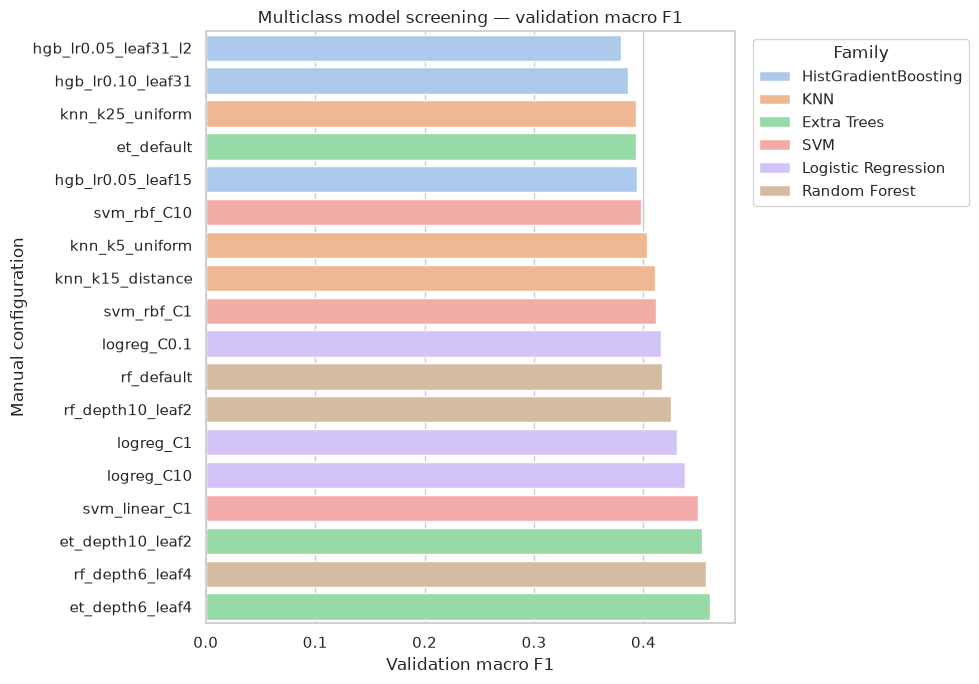

In [7]:
plot_df = results_df.loc[~results_df["is_baseline"]].sort_values("val_f1_macro", ascending=True)

plt.figure(figsize=(10, 7))
sns.barplot(data=plot_df, x="val_f1_macro", y="config_id", hue="family", dodge=False, palette="pastel")
plt.xlabel("Validation macro F1")
plt.ylabel("Manual configuration")
plt.title("Multiclass model screening — validation macro F1")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_candidate_validation_macro_f1.png", dpi=160, bbox_inches="tight")
plt.show()

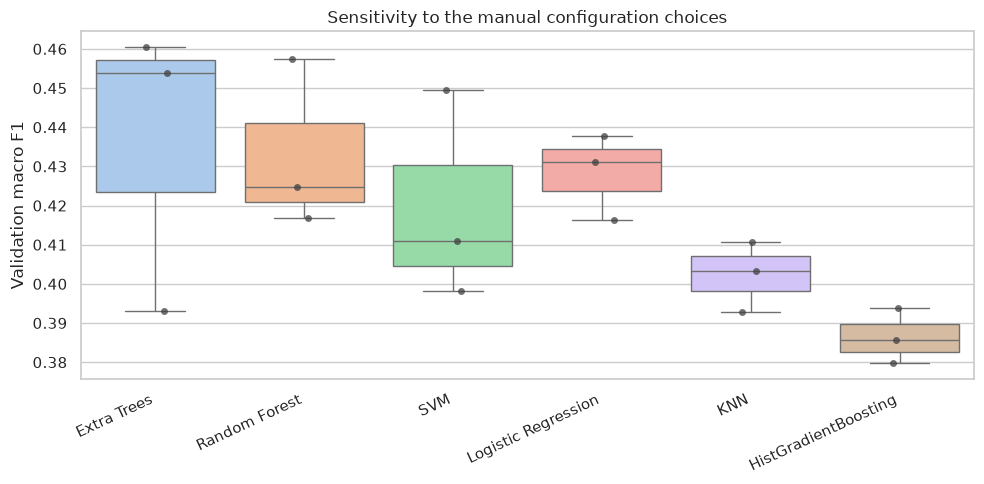

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_f1_macro",
    palette="pastel",
    showfliers=False,
)
sns.stripplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_f1_macro",
    color="0.25",
    size=5,
    alpha=0.75,
)
plt.xticks(rotation=25, ha="right")
plt.ylabel("Validation macro F1")
plt.xlabel("")
plt.title("Sensitivity to the manual configuration choices")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_family_validation_macro_f1_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
nonbaseline = results_df.loc[~results_df["is_baseline"]].copy()
family_best = (
    nonbaseline.sort_values(
        ["val_f1_macro", "val_mcc", "val_balanced_accuracy", "f1_macro_gap_train_minus_val"],
        ascending=[False, False, False, True],
    )
    .groupby("family", as_index=False, sort=False)
    .first()
)
family_best = family_best.sort_values(
    ["val_f1_macro", "val_mcc", "val_balanced_accuracy", "f1_macro_gap_train_minus_val"],
    ascending=[False, False, False, True],
).reset_index(drop=True)
family_best["family_rank"] = np.arange(1, len(family_best) + 1)

family_best.to_csv(TABLE_DIR / "family_best_results.csv", index=False)
family_best[
    [
        "family_rank",
        "family",
        "config_id",
        "val_f1_macro",
        "val_mcc",
        "val_balanced_accuracy",
        "val_accuracy",
        "val_roc_auc_ovr_macro",
        "f1_macro_gap_train_minus_val",
    ]
]

,family_rank,family,config_id,val_f1_macro,val_mcc,val_balanced_accuracy,val_accuracy,val_roc_auc_ovr_macro,f1_macro_gap_train_minus_val
0,1,Extra Trees,et_depth6_leaf4,0.460465,0.278494,0.457405,0.455556,0.717090,0.138705
1,2,Random Forest,rf_depth6_leaf4,0.457424,0.276861,0.457119,0.455556,0.713783,0.236827
2,3,SVM,svm_linear_C1,0.449412,0.275465,0.456702,0.455556,0.715299,0.051654
3,4,Logistic Regression,logreg_C10,0.437824,0.261304,0.445888,0.444444,0.712463,0.066373
4,5,KNN,knn_k15_distance,0.410788,0.215038,0.409530,0.411111,0.667487,0.589212
5,6,HistGradientBoosting,hgb_lr0.05_leaf15,0.393855,0.202688,0.402632,0.400000,0.669784,0.606145


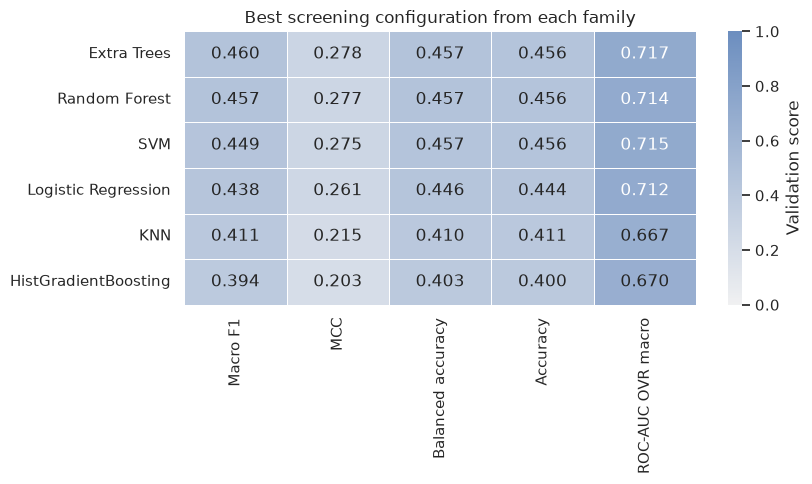

In [10]:
heatmap_metrics = [
    "val_f1_macro",
    "val_mcc",
    "val_balanced_accuracy",
    "val_accuracy",
    "val_roc_auc_ovr_macro",
]
heatmap_df = family_best.set_index("family")[heatmap_metrics].copy()
heatmap_df.columns = [
    "Macro F1",
    "MCC",
    "Balanced accuracy",
    "Accuracy",
    "ROC-AUC OVR macro",
]

plt.figure(figsize=(8.5, 5))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    cmap=PASTEL_CMAP,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Validation score"},
)
plt.title("Best screening configuration from each family")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_family_best_metric_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

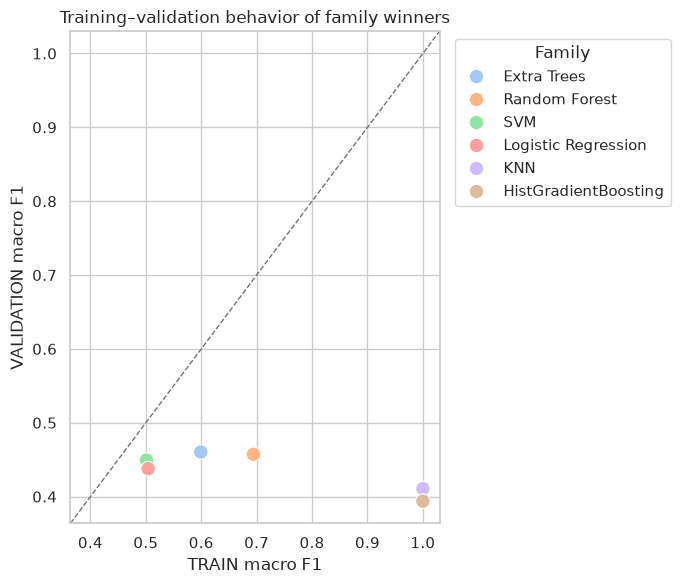

In [11]:
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=family_best,
    x="train_f1_macro",
    y="val_f1_macro",
    hue="family",
    s=110,
    palette="pastel",
)
limits = [
    min(family_best["train_f1_macro"].min(), family_best["val_f1_macro"].min()) - 0.03,
    max(family_best["train_f1_macro"].max(), family_best["val_f1_macro"].max()) + 0.03,
]
plt.plot(limits, limits, linestyle="--", linewidth=1, color="0.45")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("TRAIN macro F1")
plt.ylabel("VALIDATION macro F1")
plt.title("Training–validation behavior of family winners")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_train_validation_macro_f1.png", dpi=160, bbox_inches="tight")
plt.show()

## Select the top three algorithm families

In [12]:
top3 = family_best.head(3).copy()
top3["selected_for_optimization"] = True
top3.to_csv(TABLE_DIR / "top3_algorithms.csv", index=False)

top3[
    [
        "family_rank",
        "family",
        "config_id",
        "params",
        "val_f1_macro",
        "val_mcc",
        "val_balanced_accuracy",
        "val_roc_auc_ovr_macro",
        "f1_macro_gap_train_minus_val",
    ]
]

,family_rank,family,config_id,params,val_f1_macro,val_mcc,val_balanced_accuracy,val_roc_auc_ovr_macro,f1_macro_gap_train_minus_val
0,1,Extra Trees,et_depth6_leaf4,"{""max_depth"": 6, ""min_samples_leaf"": 4, ""n_est...",0.460465,0.278494,0.457405,0.717090,0.138705
1,2,Random Forest,rf_depth6_leaf4,"{""max_depth"": 6, ""min_samples_leaf"": 4, ""n_est...",0.457424,0.276861,0.457119,0.713783,0.236827
2,3,SVM,svm_linear_C1,"{""C"": 1.0, ""kernel"": ""linear""}",0.449412,0.275465,0.456702,0.715299,0.051654


In [13]:
top3_records = []
for _, row in top3.iterrows():
    top3_records.append(
        {
            "rank": int(row["family_rank"]),
            "family": row["family"],
            "screening_config_id": row["config_id"],
            "screening_params": json.loads(row["params"]),
            "validation_macro_f1": float(row["val_f1_macro"]),
            "validation_mcc": float(row["val_mcc"]),
            "validation_balanced_accuracy": float(row["val_balanced_accuracy"]),
            "train_validation_macro_f1_gap": float(row["f1_macro_gap_train_minus_val"]),
        }
    )

selection_manifest = {
    "dataset": DATASET,
    "task_type": "multiclass_classification",
    "screening_scope": "fixed TRAIN/VALIDATION holdout only",
    "test_used": False,
    "primary_metric": "macro F1",
    "selection_level": "algorithm family",
    "classes": CLASS_NAMES,
    "n_candidate_configurations": int(len(results_df)),
    "n_nonbaseline_families": int(len(family_best)),
    "top3": top3_records,
    "next_step": (
        "Optimize these three families using TRAIN-only stratified cross-validation. "
        "Combine each estimator with preparation_pipeline_template.joblib inside CV. "
        "Keep TEST protected."
    ),
}

with (TASK_DIR / "top3_selection_manifest.json").open("w", encoding="utf-8") as handle:
    json.dump(selection_manifest, handle, indent=2)

print(json.dumps(selection_manifest, indent=2))

{
  "dataset": "synthetic_sleep_profiles",
  "task_type": "multiclass_classification",
  "screening_scope": "fixed TRAIN/VALIDATION holdout only",
  "test_used": false,
  "primary_metric": "macro F1",
  "selection_level": "algorithm family",
  "classes": [
    "circadian_disruption",
    "healthy_sleep",
    "insomnia",
    "sleep_apnea"
  ],
  "n_candidate_configurations": 19,
  "n_nonbaseline_families": 6,
  "top3": [
    {
      "rank": 1,
      "family": "Extra Trees",
      "screening_config_id": "et_depth6_leaf4",
      "screening_params": {
        "max_depth": 6,
        "min_samples_leaf": 4,
        "n_estimators": 300
      },
      "validation_macro_f1": 0.4604649222434655,
      "validation_mcc": 0.2784942973290934,
      "validation_balanced_accuracy": 0.45740486257928115,
      "train_validation_macro_f1_gap": 0.1387048251251906
    },
    {
      "rank": 2,
      "family": "Random Forest",
      "screening_config_id": "rf_depth6_leaf4",
      "screening_params": {
     

## Class-level behavior of the selected families

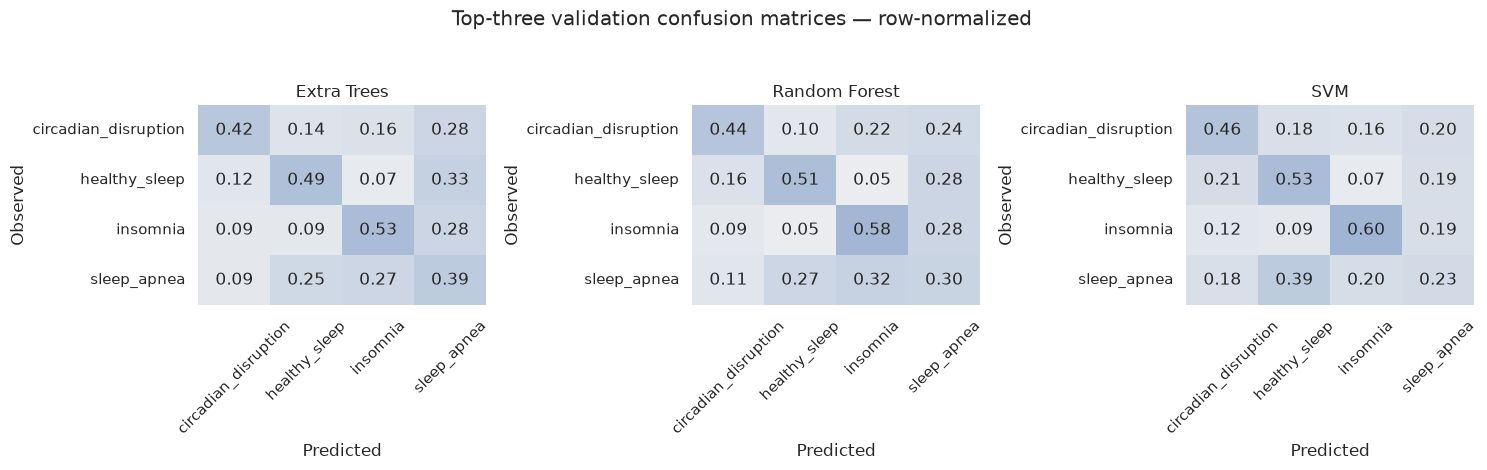

In [14]:
top3_models = {
    row["family"]: fitted_by_config[row["config_id"]]
    for _, row in top3.iterrows()
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (family, model) in zip(axes, top3_models.items()):
    pred = model.predict(X_val)
    cm = confusion_matrix(y_val, pred, labels=CLASS_IDS, normalize="true")
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap=PASTEL_CMAP,
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax,
    )
    ax.set_title(family)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Observed")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Top-three validation confusion matrices — row-normalized", y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_top3_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

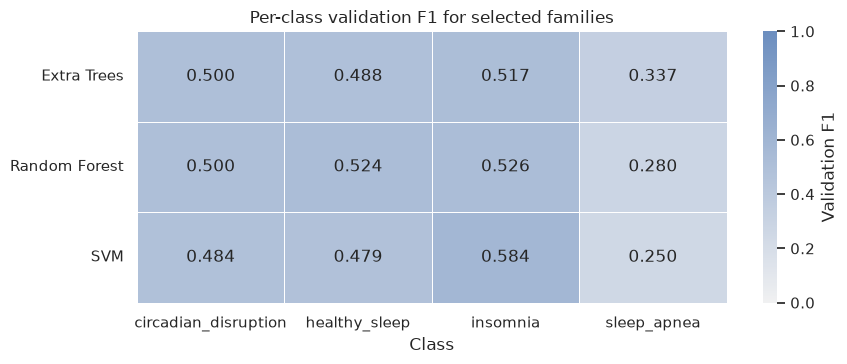

In [15]:
per_class_rows = []

for family, model in top3_models.items():
    pred = model.predict(X_val)
    class_f1 = f1_score(
        y_val,
        pred,
        labels=CLASS_IDS,
        average=None,
        zero_division=0,
    )
    for class_id, class_name, score in zip(CLASS_IDS, CLASS_NAMES, class_f1):
        per_class_rows.append(
            {
                "family": family,
                "class_id": int(class_id),
                "class_name": class_name,
                "f1": score,
            }
        )

per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(TABLE_DIR / "top3_per_class_f1.csv", index=False)

per_class_matrix = per_class_df.pivot(index="family", columns="class_name", values="f1")

plt.figure(figsize=(9, 3.8))
sns.heatmap(
    per_class_matrix,
    annot=True,
    fmt=".3f",
    cmap=PASTEL_CMAP,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Validation F1"},
)
plt.title("Per-class validation F1 for selected families")
plt.xlabel("Class")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_top3_per_class_f1_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation and hand-off

The selected family configuration is only evidence that a family is worth further investigation.
It must not be reported as an optimized model.

In the next stage:

```text
TRAIN
  ↓
stratified cross-validation
  ↓
preparation template + estimator
  ↓
hyperparameter optimization
  ↓
optimized candidates
  ↓
predefined validation comparison
```

TEST remains protected.

In [16]:
print("Screening complete.")
print("Top three families:")
for record in top3_records:
    print(
        f"  {record['rank']}. {record['family']} "
        f"(validation macro F1={record['validation_macro_f1']:.3f})"
    )
print("\nTEST was not loaded or evaluated.")
print("Results:", TASK_DIR.relative_to(ROOT))

Screening complete.
Top three families:
  1. Extra Trees (validation macro F1=0.460)
  2. Random Forest (validation macro F1=0.457)
  3. SVM (validation macro F1=0.449)

TEST was not loaded or evaluated.
Results: results/synthetic_sleep_profiles/model_screening
